# Predictive analysis

Use a stratified 80/20 split (seed 42). Fit preprocessing within fivefold stratified training cross-validation. Compare LR, SVM, Decision Tree and KNN. Select by CV only. Exclude outcome and landing-pad information, serial identifiers and cumulative reuse counts. This independent protocol differs from historical lab answer keys.

Generated and executed on 2026-10-09. See README.md for provenance and limitations.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
ROOT = Path.cwd()
if ROOT.name == "notebooks": ROOT = ROOT.parent
sys.path.insert(0,str(ROOT))
import pipeline

In [2]:
d=pipeline.wrangle()
scores=pipeline.train(d)
print(scores.to_string(index=False))

              model  cv_accuracy  test_accuracy  test_f1                                                      best_params
                SVM     0.888571       0.777778 0.857143 {"model__C": 1, "model__gamma": "scale", "model__kernel": "rbf"}
      Decision Tree     0.874286       0.777778 0.833333            {"model__max_depth": 3, "model__min_samples_leaf": 2}
                KNN     0.861905       0.777778 0.857143           {"model__n_neighbors": 7, "model__weights": "uniform"}
Logistic Regression     0.848571       0.777778 0.857143                                                {"model__C": 0.1}


In [3]:
print((ROOT/"results/summary.json").read_text())

{
  "rows": 90,
  "class1": 60,
  "class0": 30,
  "train_n": 72,
  "test_n": 18,
  "selected_model": "SVM",
  "cm": [
    [
      2,
      4
    ],
    [
      0,
      12
    ]
  ],
  "test_accuracy": 0.7777777777777778,
  "features": [
    "PayloadMass",
    "Flights",
    "Block",
    "Orbit",
    "LaunchSite",
    "GridFins",
    "Reused",
    "Legs"
  ],
  "excluded": [
    "Outcome",
    "LandingPad",
    "ReusedCount",
    "Serial",
    "Date",
    "FlightNumber",
    "BoosterVersion",
    "Longitude",
    "Latitude"
  ],
  "protocol": "Stratified 80/20 split, seed 42, fivefold stratified training CV, preprocessing fit within CV"
}


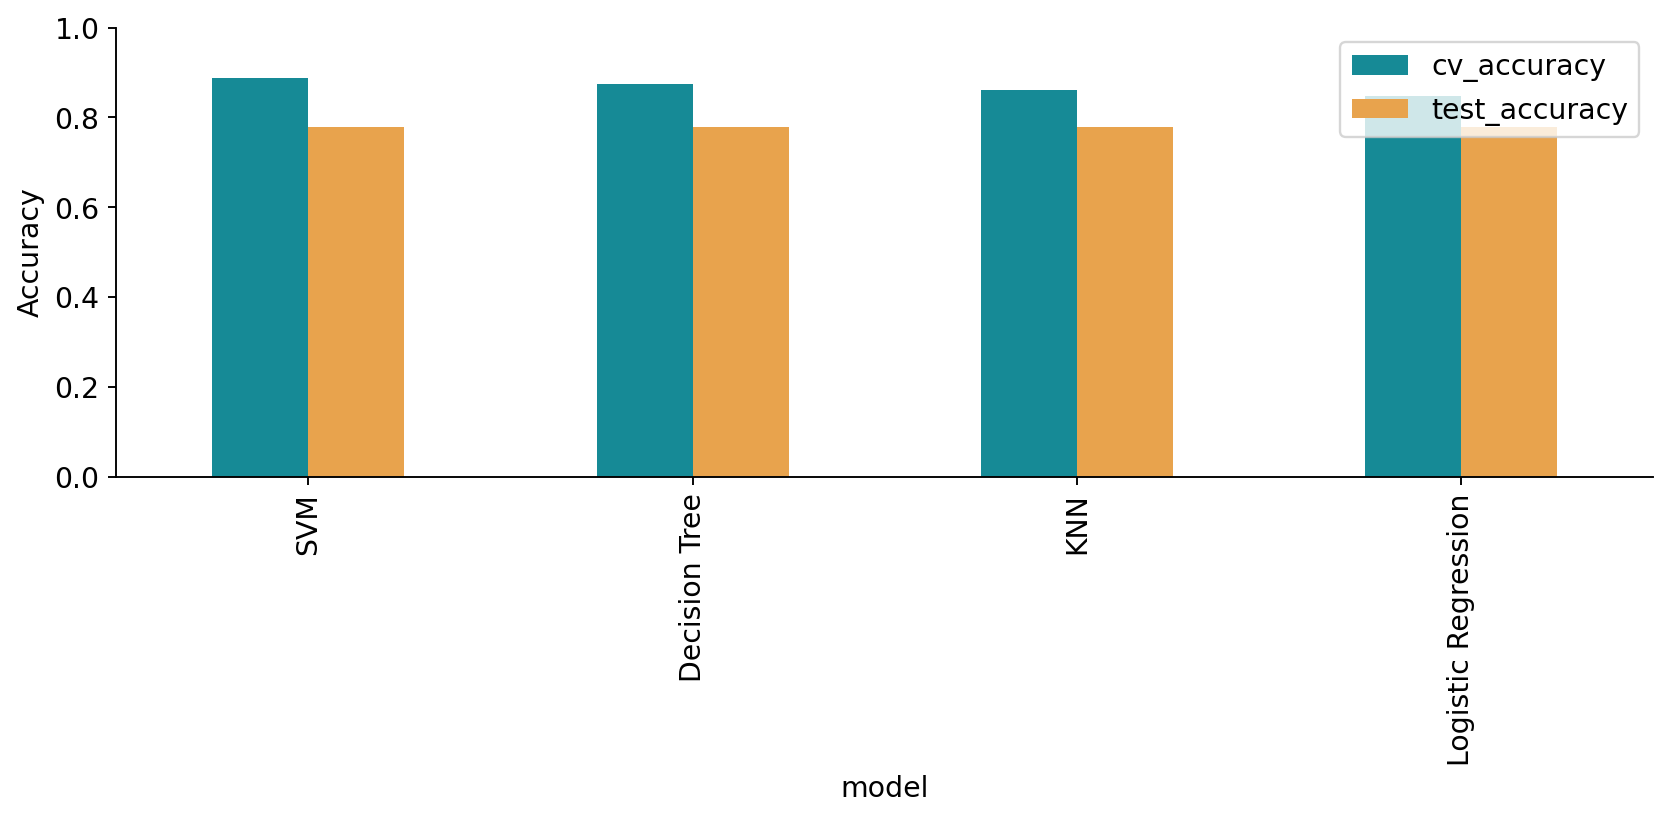

In [4]:
from IPython.display import display, Image
display(Image(filename=str(ROOT/"results/models.png")))

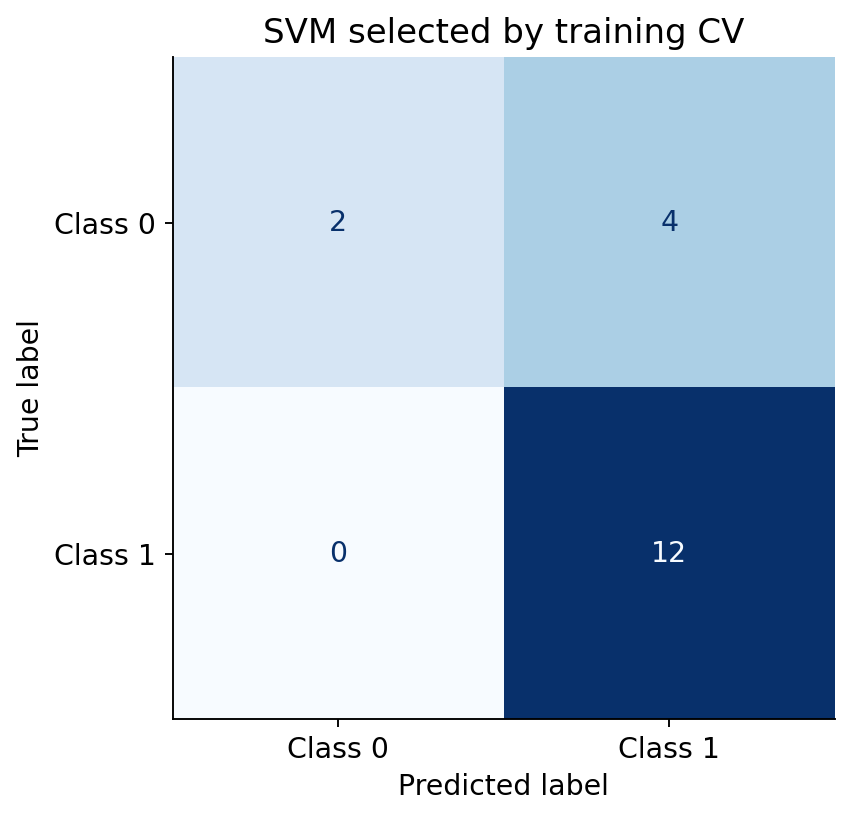

In [5]:
from IPython.display import display, Image
display(Image(filename=str(ROOT/"results/confusion_matrix.png")))